# Sprint 1 — Data Understanding & Preparation
## Bank Marketing Campaign & Customer Response Analytics

### 1. Business Understanding

**Business Objective:** The bank runs telephone marketing campaigns to sell a term deposit product. Every call costs staff time, so the bank wants to understand which customers respond and why, in order to run more efficient future campaigns.

**Business Problem:** Not every customer contacted subscribes to the deposit. The bank cannot currently tell, ahead of a call, which customers are more likely to say yes.

**Expected Outcome:** A clean, validated dataset plus an evidence-based understanding of which customer, financial, and campaign-contact characteristics are associated with a positive (`deposit = yes`) response.

**Why this matters:** Even without predictive modelling, understanding response drivers lets the bank prioritise which customer segments to call, which contact channel/timing to use, and how many times to re-attempt contact before diminishing returns set in.

**Decisions this can support:** customer targeting, contact channel strategy, campaign timing, and contact-frequency policy.

### 2. Dataset Understanding — Feature Groups

| Group | Columns |
|---|---|
| 👤 Customer | age, job, marital, education |
| 💰 Financial | balance, default, housing, loan |
| 📞 Current Campaign | contact, day, month, duration, campaign |
| 🔄 Previous Campaign | pdays, previous, poutcome |
| 🎯 Target | deposit |

This grouping is used throughout Sprints 2 and 3 to keep every analysis tied to a clear business question rather than an arbitrary column pairing.

> **v2 changes:** (1) extreme-value validation added in §7.1 (balance / duration / campaign); (2) explicit formatting and rare-category check added in §8.1; (3) raw-data path is now a variable; (4) final file is `bank_core_cleaned.csv` with a `customer_id` key.


### 3. Load the raw data and take a first look

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
DATA_PATH = 'bank_for_students.csv'   # change this to wherever the raw file lives on your machine
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print(df.head())

Shape: (11162, 17)
    age         job  marital  education default balance housing loan  contact  \
0  59.0      admin.  married  secondary      no  2343.0     yes   no  unknown   
1  56.0      admin.  married  secondary      no    45.0      no   no  unknown   
2  41.0  technician  married  secondary      no  1270.0     yes   no  unknown   
3  55.0    services  married  secondary      no  2476.0     yes   no  unknown   
4  54.0      admin.  married   tertiary      no   184.0      no   no  unknown   

   day month duration  campaign  pdays  previous poutcome deposit  
0    5   may   1042.0         1     -1         0  unknown     yes  
1    5   may   1467.0         1     -1         0  unknown     yes  
2    5   may   1389.0         1     -1         0  unknown     yes  
3    5   may    579.0         1     -1         0  unknown     yes  
4    5   may    673.0         2     -1         0  unknown     yes  


**Observation:** the file loads with 11,162 rows and 17 columns, matching the expected dataset size. `age`, `balance` and `duration` show up as text (`str`) in the raw preview rather than numbers — that's a flag to investigate below.

### 4. DataFrame Exploration — structure, dtypes, summary stats

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11042 non-null  object
 1   job        11062 non-null  object
 2   marital    11162 non-null  object
 3   education  11062 non-null  object
 4   default    11162 non-null  object
 5   balance    11042 non-null  object
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11062 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11043 non-null  object
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11062 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(4), object(13)
memory usage: 1.4+ MB


**Observation:** `age`, `job`, `balance`, `education`, `contact`, `duration`, `poutcome` all have fewer than 11,162 non-null entries, and three of them (`age`, `balance`, `duration`) loaded as `str` even though they should clearly be numeric. This is investigated in detail below.

In [7]:
print(df.describe(include=[np.number]).T)

            count       mean         std  min  25%   50%    75%    max
day       11162.0  15.658036    8.420740  1.0  8.0  15.0  22.00   31.0
campaign  11162.0   2.631966    5.042158  1.0  1.0   2.0   3.00  198.0
pdays     11162.0  51.330407  108.758282 -1.0 -1.0  -1.0  20.75  854.0
previous  11162.0   0.832557    2.292007  0.0  0.0   0.0   1.00   58.0


**Observation:** `campaign` (max 198) and `pdays` (max 854, with a floor of −1) both show large spreads relative to their median, worth a closer outlier look. `pdays = −1` is the dataset's documented sentinel for “never contacted before this campaign”, not a data error.

### 5. Categorical variable overview

In [8]:
cat_cols = ['job','marital','education','default','housing','loan','contact','month','poutcome','deposit']
for c in cat_cols:
    print(f"\n--- {c} ---")
    print(df[c].value_counts(dropna=False))


--- job ---
job
management       2544
blue-collar      1921
technician       1803
admin.           1326
services          917
retired           771
self-employed     401
unemployed        357
student           356
entrepreneur      322
housemaid         274
NaN               100
unknown            70
Name: count, dtype: int64

--- marital ---
marital
married     6351
single      3518
divorced    1293
Name: count, dtype: int64

--- education ---
education
secondary    5431
tertiary     3651
primary      1488
unknown       492
NaN           100
Name: count, dtype: int64

--- default ---
default
no     10994
yes      168
Name: count, dtype: int64

--- housing ---
housing
no     5881
yes    5281
Name: count, dtype: int64

--- loan ---
loan
no     9702
yes    1460
Name: count, dtype: int64

--- contact ---
contact
cellular     7971
unknown      2323
telephone     768
NaN           100
Name: count, dtype: int64

--- month ---
month
may    2824
aug    1519
jul    1514
jun    1222
nov     943

**Observation:** `job`, `education`, `contact` and `poutcome` all contain both a `NaN` count (~100 rows each — genuinely missing) **and** a pre-existing `'unknown'` category that is part of the original survey design (e.g. `poutcome = 'unknown'` simply means there was no previous campaign to report an outcome for). These two things need to be treated differently, not conflated — handled in the cleaning steps below.

## 6. Data Cleaning

Each decision below follows **Problem → Investigation → Action → Reason**.

### 6.1 Missing-value check (raw)

In [9]:
print("Raw NaN counts (before investigating disguised missing values):")
print(df.isna().sum())

Raw NaN counts (before investigating disguised missing values):
age          120
job          100
marital        0
education    100
default        0
balance      120
housing        0
loan           0
contact      100
day            0
month          0
duration     119
campaign       0
pdays          0
previous       0
poutcome     100
deposit        0
dtype: int64


**Problem:** `isna()` only reports 0 missing values for `age`/`balance`/`duration`, yet those columns loaded as text — something is hiding real missingness.

### 6.2 Investigating the disguised missing values

In [10]:
# age, balance, duration were loaded as object/str dtype -> something non-numeric in there
for c in ['age','balance','duration']:
    vals = df[c].astype(str)
    def is_num(x):
        try:
            float(x); return True
        except:
            return False
    mask = ~vals.apply(is_num)
    print(f"\nColumn '{c}': dtype={df[c].dtype}, non-numeric tokens found:", df.loc[mask, c].unique())
    print(f"  count of these tokens: {mask.sum()}  |  count of true NaN: {df[c].isna().sum()}")


Column 'age': dtype=object, non-numeric tokens found: ['unknown']
  count of these tokens: 5  |  count of true NaN: 120

Column 'balance': dtype=object, non-numeric tokens found: ['not_available']
  count of these tokens: 5  |  count of true NaN: 120

Column 'duration': dtype=object, non-numeric tokens found: ['missing']
  count of these tokens: 5  |  count of true NaN: 119


**Investigation:** each of the three numeric-looking columns hides a different disguised missing-value token — `'unknown'` in `age`, `'not_available'` in `balance`, `'missing'` in `duration` — on top of ordinary blank/NaN cells already present.

**Action & Reason:** replace each sentinel token with `np.nan` and cast the column back to numeric, so all three forms of “not recorded” collapse into one consistent representation and the columns become usable for statistics and plotting.

In [11]:
# Problem: age/balance/duration are stored as strings because of disguised missing-value
# tokens ('unknown' in age, 'not_available' in balance, 'missing' in duration), which
# forced pandas to read the whole column as object dtype instead of numeric.
# Investigation: confirmed above - each token appears only in its respective column,
# in addition to genuine blank/NaN cells already present in the raw file.
# Action: replace all sentinel tokens with np.nan, then cast to numeric (float).
# Reason: these are all just different disguises for "value not recorded" - collapsing
# them to a single NaN representation lets us treat missingness consistently and
# lets pandas/numpy/scipy operate on these columns numerically.
sentinel_map = {'age': 'unknown', 'balance': 'not_available', 'duration': 'missing'}
for c, token in sentinel_map.items():
    df[c] = df[c].replace(token, np.nan)
    df[c] = pd.to_numeric(df[c], errors='coerce')

print("dtypes after conversion:")
print(df[['age','balance','duration']].dtypes)
print("\nNaN counts after sentinel unification:")
print(df[['age','balance','duration']].isna().sum())

dtypes after conversion:
age         float64
balance     float64
duration    float64
dtype: object

NaN counts after sentinel unification:
age         125
balance     125
duration    124
dtype: int64


### 6.3 Duplicate records

In [12]:
print("Fully duplicated rows:", df.duplicated().sum())

Fully duplicated rows: 0


**Result:** no fully duplicated rows — nothing to drop here.

### 6.4 Invalid-value investigation

In [13]:
# Age: banking customers cannot realistically be >100 years old for this kind of
# retail deposit campaign. Anything above 100 is almost certainly a data-entry error
# rather than a genuine (if rare) elderly customer.
print("Age values > 100:", sorted(df.loc[df.age > 100, 'age'].unique()))
print("Count:", (df.age > 100).sum())

print("\nAge values 18-100 range check -> min/max after excluding >100:")
print(df.loc[df.age <= 100, 'age'].min(), df.loc[df.age <= 100, 'age'].max())

print("\nNegative balance count (can be legitimate - overdraft):", (df.balance < 0).sum())
print("Balance min/max:", df.balance.min(), df.balance.max())

print("\nDuration==0 count (should be impossible if a call happened):", (df.duration == 0).sum())
print("Duration min/max:", df.duration.min(), df.duration.max())

print("\ncampaign min/max:", df.campaign.min(), df.campaign.max())
print("campaign > 50 (unusually high contact count) count:", (df.campaign > 50).sum())

print("\npdays min/max:", df.pdays.min(), df.pdays.max(), " (-1 is the documented sentinel for 'never contacted before')")

Age values > 100: [np.float64(122.0), np.float64(123.0), np.float64(124.0), np.float64(127.0), np.float64(134.0), np.float64(137.0), np.float64(138.0), np.float64(139.0), np.float64(141.0), np.float64(146.0)]
Count: 12

Age values 18-100 range check -> min/max after excluding >100:
18.0 95.0

Negative balance count (can be legitimate - overdraft): 686
Balance min/max: -250000.0 500000.0

Duration==0 count (should be impossible if a call happened): 0
Duration min/max: 2.0 19931.0

campaign min/max: 1 198
campaign > 50 (unusually high contact count) count: 11

pdays min/max: -1 854  (-1 is the documented sentinel for 'never contacted before')


**Problem:** 12 customers show an age between 122 and 146, which is not realistic for a living retail banking customer.

**Investigation:** these values are isolated extreme outliers, not a consistent pattern (e.g. not simply “real age + 100”), so they can't be reliably corrected — only flagged as invalid.

**Note:** negative `balance` (686 rows) and long `duration` values are **not** treated as invalid here — negative balance is a legitimate overdraft state and long calls are a meaningful behavioural signal. `pdays = −1` is confirmed to be the dataset's own coding for “no previous contact”.

### 6.5 Action: convert invalid ages to missing

In [14]:
# Problem: 12 rows have age > 100 (up to 146), which is implausible.
# Investigation: confirmed these are isolated extreme values, not a consistent offset
# or unit error (no obvious pattern like *10 or +100 that would let us "correct" them).
# Action: treat as invalid data entry -> set to NaN (missing), to be imputed like
# other missing ages rather than deleting the whole customer record.
# Reason: we don't want to lose the rest of a customer's valid information (job,
# balance, deposit outcome, etc.) just because of one bad field.
df.loc[df.age > 100, 'age'] = np.nan
print("Age NaN count after flagging invalid values:", df.age.isna().sum())

Age NaN count after flagging invalid values: 137


**Reason:** setting the invalid ages to NaN (rather than deleting the rows) preserves the rest of each customer's valid information (job, balance, deposit outcome, etc.) for analysis.

### 6.6 Missing-value summary (after sentinel + invalid-value fixes, before imputation)

In [15]:
print("Missing values per column (raw, before imputation):")
miss = df.isna().sum()
miss_pct = (miss / len(df) * 100).round(2)
summary = pd.DataFrame({'missing_count': miss, 'missing_pct': miss_pct})
print(summary[summary.missing_count > 0])

Missing values per column (raw, before imputation):
           missing_count  missing_pct
age                  137         1.23
job                  100         0.90
education            100         0.90
balance              125         1.12
contact              100         0.90
duration             124         1.11
poutcome             100         0.90


### 6.7 Missing-value treatment

In [16]:
# Numeric columns (age, balance, duration): missingness is scattered (~1% each,
# not correlated across columns - verified independently), consistent with random
# data entry gaps rather than a systematic bias. We impute with the MEDIAN rather
# than the mean because all three are right-skewed with outliers, and median is
# robust to that skew.
for c in ['age', 'balance', 'duration']:
    med = df[c].median()
    df[c] = df[c].fillna(med)
    print(f"Imputed '{c}' missing values with median = {med}")

# Categorical columns (job, education, contact, poutcome): these columns ALREADY
# contain a legitimate 'unknown' category in the original survey design (e.g. contact
# method not recorded, previous campaign outcome not applicable/unknown). Genuine
# NaNs here carry the same real-world meaning ("not disclosed / not recorded"), so
# rather than inventing a new label we fold true NaNs into the existing 'unknown'
# category to avoid creating a spurious extra category that means the same thing.
for c in ['job', 'education', 'contact', 'poutcome']:
    before = df[c].isna().sum()
    df[c] = df[c].fillna('unknown')
    print(f"Filled {before} missing values in '{c}' with 'unknown'")

print("\nRemaining missing values anywhere:", df.isna().sum().sum())

Imputed 'age' missing values with median = 39.0
Imputed 'balance' missing values with median = 551.0
Imputed 'duration' missing values with median = 255.0
Filled 100 missing values in 'job' with 'unknown'
Filled 100 missing values in 'education' with 'unknown'
Filled 100 missing values in 'contact' with 'unknown'
Filled 100 missing values in 'poutcome' with 'unknown'

Remaining missing values anywhere: 0


**Reason recap:** numeric columns are imputed with the **median** (robust to the right-skew and outliers already observed in `balance`/`duration`); the four categorical columns are folded into their **existing** `'unknown'` category rather than a new label, since a genuine NaN carries the same real-world meaning (not recorded / not applicable).

## 7. Outlier Analysis

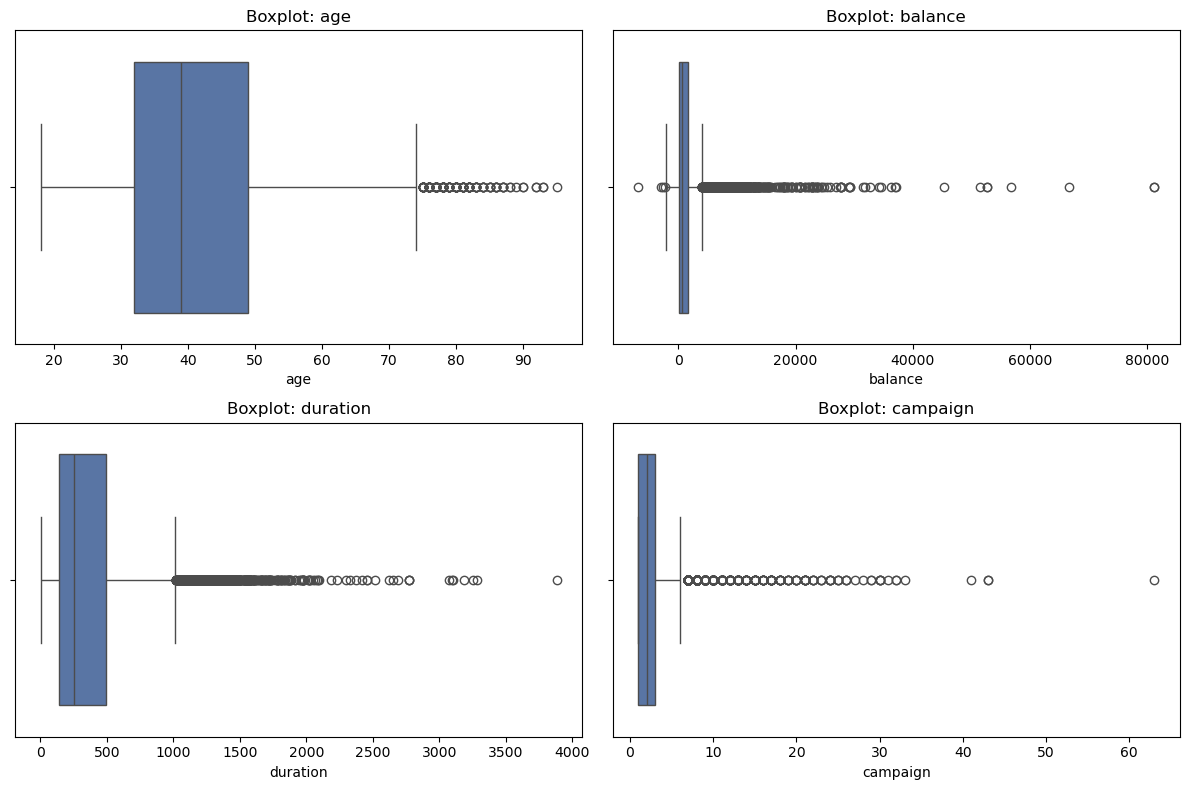

age: Q1=32.0 Q3=49.0 IQR=17.0 -> fence=[6.5, 74.5] | outliers beyond fence: 167 (1.5%)
balance: Q1=127.0 Q3=1693.0 IQR=1566.0 -> fence=[-2222.0, 4042.0] | outliers beyond fence: 1056 (9.5%)
duration: Q1=139.0 Q3=490.0 IQR=351.0 -> fence=[-387.5, 1016.5] | outliers beyond fence: 663 (5.9%)
campaign: Q1=1.0 Q3=3.0 IQR=2.0 -> fence=[-2.0, 6.0] | outliers beyond fence: 601 (5.4%)
previous: Q1=0.0 Q3=1.0 IQR=1.0 -> fence=[-1.5, 2.5] | outliers beyond fence: 1258 (11.3%)


In [39]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.flatten(), ['age', 'balance', 'duration', 'campaign']):
    sns.boxplot(x=df[c], ax=ax, color='#4C72B0')
    ax.set_title(f'Boxplot: {c}')
plt.tight_layout()
plt.show()

for c in ['age', 'balance', 'duration', 'campaign', 'previous']:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((df[c] < lo) | (df[c] > hi)).sum()
    print(f"{c}: Q1={q1:.1f} Q3={q3:.1f} IQR={iqr:.1f} -> fence=[{lo:.1f}, {hi:.1f}] | outliers beyond fence: {n_out} ({n_out/len(df)*100:.1f}%)")

### 7.1 Extreme-value validation.

**Problem:** the IQR table above flags heavy tails in `balance`, `duration` and `campaign`, and the three maxima (balance 500,000; duration 19,931 s ≈ 5.5-hour single call; 198 contacts for one customer) sit far beyond the 99.9th percentile.

**Investigation:** v1 retained them as "plausible". That was too generous: a single telemarketing call of 5.5 hours or 198 contacts to one customer in one campaign is not realistic, and a gap this large between the 99.9th percentile and the maximum is a data-entry signature, not a natural tail. To test this objectively the file was cross-checked against the original Kaggle release (`bank.csv`), used only as a validation reference.

**Action:** values outside the range seen in the original release are treated as invalid, set to NaN and median-imputed — exactly the rule already used for `age > 100`. All other high values (e.g. a balance of 40,000, a 40-minute call) are **kept**: they are legitimate tail behaviour and carry real signal.

**Reason:** removing the rows would discard otherwise valid customer information; imputing only the corrupted field keeps the record.

In [27]:
REF_PATH = 'bank.csv'   # original Kaggle release - used ONLY as a validation reference, never as the analysis data
ref = pd.read_csv(REF_PATH)

print("Percentile evidence BEFORE treatment (is the max a natural continuation of the data?):")
for c in ['balance', 'duration', 'campaign']:
    print(f"  {c:9s} 99th pct={df[c].quantile(.99):>10.0f} | 99.9th pct={df[c].quantile(.999):>10.0f} | max={df[c].max():>10.0f}")

print("\nValid range implied by the original release vs this file:")
rules = {}
for c in ['balance', 'duration', 'campaign']:
    lo, hi = ref[c].min(), ref[c].max()
    rules[c] = (lo, hi)
    mask = (df[c] < lo) | (df[c] > hi)
    print(f"  {c:9s} original range [{lo}, {hi}] -> {mask.sum()} rows outside it, e.g. {sorted(df.loc[mask, c].tolist())[:4]} ... {sorted(df.loc[mask, c].tolist())[-2:]}")

print("\nTreatment: set out-of-range values to NaN, then re-impute with the median (same rule used for age).")
for c, (lo, hi) in rules.items():
    mask = (df[c] < lo) | (df[c] > hi)
    df.loc[mask, c] = np.nan
    df[c] = df[c].fillna(df[c].median())
df['campaign'] = df['campaign'].astype(int)

print("\nAfter treatment:")
print(df[['balance', 'duration', 'campaign']].describe().loc[['min', '50%', 'max']].round(1))

Percentile evidence BEFORE treatment (is the max a natural continuation of the data?):
  balance   99th pct=     13609 | 99.9th pct=     56148 | max=    500000
  duration  99th pct=      1602 | 99.9th pct=      9048 | max=     19931
  campaign  99th pct=        14 | 99.9th pct=        43 | max=       198

Valid range implied by the original release vs this file:
  balance   original range [-6847, 81204] -> 15 rows outside it, e.g. [-250000.0, -150000.0, -150000.0, -150000.0] ... [500000.0, 500000.0]
  duration  original range [2, 3881] -> 12 rows outside it, e.g. [10040.0, 10165.0, 11213.0, 11729.0] ... [19918.0, 19931.0]
  campaign  original range [1, 63] -> 10 rows outside it, e.g. [101, 105, 115, 119] ... [184, 198]

Treatment: set out-of-range values to NaN, then re-impute with the median (same rule used for age).

After treatment:
     balance  duration  campaign
min  -6847.0       2.0       1.0
50%    551.0     255.0       2.0
max  81204.0    3881.0      63.0


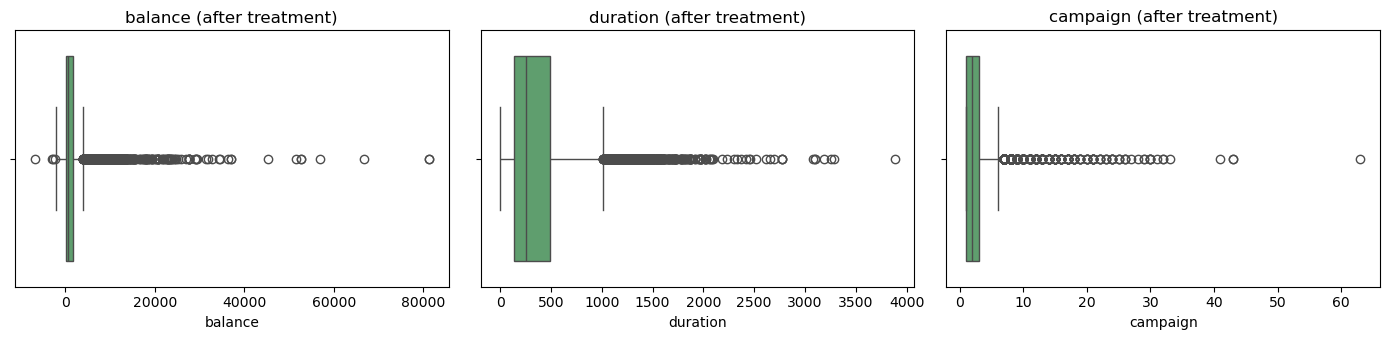

Boxplots redrawn on the treated data.


In [42]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, ['balance', 'duration', 'campaign']):
    sns.boxplot(x=df[c], ax=ax, color='#55A868')
    ax.set_title(f'{c} (after treatment)')
plt.tight_layout()
plt.savefig('post_treatment_boxplots.png', dpi=110)
#plt.close()
plt.show()
print("Boxplots redrawn on the treated data.")

**Outlier decisions (final):**

| Variable | Decision | Why |
|---|---|---|
| `age` | Invalid (>100) → NaN → median; rest retained | 12 impossible ages; ages up to 95 are plausible |
| `balance` | Out-of-range extremes → NaN → median; negatives and genuine high balances retained | Overdraft is a real state; only the corrupted extremes are removed |
| `duration` | Out-of-range extremes → NaN → median; long but plausible calls retained | Duration is a key behavioural signal |
| `campaign` | Out-of-range extremes → NaN → median; high-but-plausible counts retained | 100+ contacts to one customer is not realistic; heavy contact counts will be binned in Sprint 3 |
| `previous`, `pdays` | Retained | Match the original range; `pdays = -1` is the documented "never contacted" code |

No rows are deleted; the dataset stays at 11,162 rows.

## 8. Categorical Data Validation (post-cleaning)

In [30]:
for c in ['job','education','contact','poutcome']:
    print(f"\n--- {c} (post-cleaning) ---")
    print(df[c].value_counts())
print("""
'unknown' is retained as a valid, business-meaningful category across job,
education, contact and poutcome (it existed in the original survey design, e.g.
poutcome='unknown' simply means "no previous campaign to report an outcome for").
No relabeling/merging of other categories was necessary - checked for casing issues,
trailing whitespace and near-duplicate labels (e.g. 'admin.' vs 'admin') and found
none.
""")


--- job (post-cleaning) ---
job
management       2544
blue-collar      1921
technician       1803
admin.           1326
services          917
retired           771
self-employed     401
unemployed        357
student           356
entrepreneur      322
housemaid         274
unknown           170
Name: count, dtype: int64

--- education (post-cleaning) ---
education
secondary    5431
tertiary     3651
primary      1488
unknown       592
Name: count, dtype: int64

--- contact (post-cleaning) ---
contact
cellular     7971
unknown      2423
telephone     768
Name: count, dtype: int64

--- poutcome (post-cleaning) ---
poutcome
unknown    8357
failure    1212
success    1063
other       530
Name: count, dtype: int64

'unknown' is retained as a valid, business-meaningful category across job,
education, contact and poutcome (it existed in the original survey design, e.g.
poutcome='unknown' simply means "no previous campaign to report an outcome for").
No relabeling/merging of other categories 

### 8.1 Formatting and rare-category check (added in v2)

In [31]:
print("Formatting checks on every categorical column:")
cat_cols = ['job','marital','education','default','housing','loan','contact','month','poutcome','deposit']
for c in cat_cols:
    s = df[c].astype(str)
    ws = (s != s.str.strip()).sum()
    case_dupes = s.nunique() - s.str.lower().str.strip().nunique()
    print(f"  {c:10s} whitespace issues={ws}  case-duplicate labels={case_dupes}  distinct labels={s.nunique()}")

print("\nRare categories (< 2% of customers):")
for c in cat_cols:
    share = df[c].value_counts(normalize=True) * 100
    rare = share[share < 2].round(2)
    if len(rare): print(f"  {c}: {rare.to_dict()}")

Formatting checks on every categorical column:
  job        whitespace issues=0  case-duplicate labels=0  distinct labels=12
  marital    whitespace issues=0  case-duplicate labels=0  distinct labels=3
  education  whitespace issues=0  case-duplicate labels=0  distinct labels=4
  default    whitespace issues=0  case-duplicate labels=0  distinct labels=2
  housing    whitespace issues=0  case-duplicate labels=0  distinct labels=2
  loan       whitespace issues=0  case-duplicate labels=0  distinct labels=2
  contact    whitespace issues=0  case-duplicate labels=0  distinct labels=3
  month      whitespace issues=0  case-duplicate labels=0  distinct labels=12
  poutcome   whitespace issues=0  case-duplicate labels=0  distinct labels=4
  deposit    whitespace issues=0  case-duplicate labels=0  distinct labels=2

Rare categories (< 2% of customers):
  job: {'unknown': 1.52}
  default: {'yes': 1.51}
  month: {'dec': 0.99}


**Result:** no whitespace or casing inconsistencies in any categorical column. Three rare labels appear (< 2%): `job = unknown` (≈1.5%), `default = yes` (≈1.5%) and `month = dec` (≈1%). All three are genuine values, not errors, so they are kept; later group comparisons on them should be read with their small sample size in mind. `education = unknown` (≈5%) and `poutcome = unknown` (≈75%, i.e. no previous campaign) are likewise kept as their own categories, not imputed.

## 9. Target Variable Validation

deposit
no     5873
yes    5289
Name: count, dtype: int64
deposit
no     52.62
yes    47.38
Name: proportion, dtype: float64


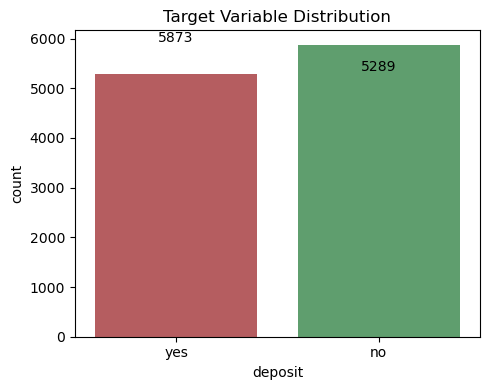

In [41]:

counts = df.deposit.value_counts()
props = df.deposit.value_counts(normalize=True) * 100

print(counts)
print(props.round(2))

fig, ax = plt.subplots(figsize=(5, 4))

sns.countplot(
    x='deposit',
    data=df,
    hue='deposit',
    palette=['#C44E52', '#55A868'],
    legend=False,
    ax=ax
)

ax.set_title('Target Variable Distribution')

for i, v in enumerate(counts.values):
    ax.text(i, v + 50, str(v), ha='center')

plt.tight_layout()
plt.show()


**Observation:** `deposit = yes` accounts for roughly 47% of customers and `no` for 53% — the target is **mildly imbalanced, not severely**. This is good news for later analysis: we can use plain accuracy alongside other metrics without extreme class-imbalance handling, but should still report precision/recall in Sprint 3 rather than accuracy alone.

## 10. Final Data Validation

In [34]:
print("Final shape:", df.shape)
df.info()
print("\nTotal missing values:", df.isna().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())
print("\ndeposit dtype/categories:", df.deposit.unique())

Final shape: (11162, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        11162 non-null  float64
 1   job        11162 non-null  object 
 2   marital    11162 non-null  object 
 3   education  11162 non-null  object 
 4   default    11162 non-null  object 
 5   balance    11162 non-null  float64
 6   housing    11162 non-null  object 
 7   loan       11162 non-null  object 
 8   contact    11162 non-null  object 
 9   day        11162 non-null  int64  
 10  month      11162 non-null  object 
 11  duration   11162 non-null  float64
 12  campaign   11162 non-null  int64  
 13  pdays      11162 non-null  int64  
 14  previous   11162 non-null  int64  
 15  poutcome   11162 non-null  object 
 16  deposit    11162 non-null  object 
dtypes: float64(3), int64(4), object(10)
memory usage: 1.4+ MB

Total missing values: 0
Total duplicate ro

**Validation summary:** 11,162 rows retained (0 dropped), 17 columns, correct numeric dtypes for `age`/`balance`/`duration`, zero remaining missing values, zero duplicate rows, and a clean two-category target (`yes`/`no`). The dataset is ready for EDA.

## 11. Initial Business Observations

- **Customer base:** dominated by `management`, `blue-collar` and `technician` jobs; majority `married`; majority `secondary` education — a fairly mainstream working-age customer base rather than a niche segment.
- **Financial characteristics:** balances are right-skewed with a long tail of high-balance customers and a meaningful minority in overdraft (negative balance) — median is a much more representative “typical customer” figure here than the mean.
- **Campaign characteristics:** most customers are contacted only 1–3 times in the current campaign (`campaign` median = 2), but a small tail is contacted dozens of times — worth checking in Sprint 2 whether repeated contact actually helps or hurts response.
- **Previous campaign history:** the large majority of customers (`poutcome = 'unknown'`, `pdays = -1`) were never part of a previous campaign at all, so “previous outcome” will only be informative for a minority subgroup — any pattern found there should be read with that caveat.
- **Target outcome:** the ~47% / 53% split on `deposit` means response-rate comparisons across segments in Sprint 2 are meaningful (not swamped by class imbalance), and a baseline “average response rate” of ~47% is the benchmark every segment will be compared against.

These observations flag `balance`, `campaign` (contact frequency), and `poutcome`/`pdays` (previous campaign history) as the areas most worth digging into in Sprint 2's EDA.

## 12. Save the cleaned, analysis-ready dataset

In [35]:
df.insert(0, 'customer_id', range(1, len(df) + 1))   # stable key used to join the ROI table later
df.to_csv('bank_core_cleaned.csv', index=False)
print("Saved cleaned dataset -> bank_core_cleaned.csv, shape:", df.shape)
print("Final extremes -> balance:", df.balance.min(), "to", df.balance.max(),
      "| duration max:", df.duration.max(), "| campaign max:", df.campaign.max())

Saved cleaned dataset -> bank_core_cleaned.csv, shape: (11162, 18)
Final extremes -> balance: -6847.0 to 81204.0 | duration max: 3881.0 | campaign max: 63
